In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### Loading The Dataset

In [2]:
df = pd.read_csv("AI_Impact_on_Jobs_2030.csv")
df.head()

,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Risk_Category,Skill_1,Skill_2,Skill_3,Skill_4,Skill_5,Skill_6,Skill_7,Skill_8,Skill_9,Skill_10
0,Security Guard,45795,28,Master's,0.18,1.28,0.85,High,0.45,0.10,0.46,0.33,0.14,0.65,0.06,0.72,0.94,0.00
1,Research Scientist,133355,20,PhD,0.62,1.11,0.05,Low,0.02,0.52,0.40,0.05,0.97,0.23,0.09,0.62,0.38,0.98
2,Construction Worker,146216,2,High School,0.86,1.18,0.81,High,0.01,0.94,0.56,0.39,0.02,0.23,0.24,0.68,0.61,0.83
3,Software Engineer,136530,13,PhD,0.39,0.68,0.60,Medium,0.43,0.21,0.57,0.03,0.84,0.45,0.40,0.93,0.73,0.33
4,Financial Analyst,70397,22,High School,0.52,1.46,0.64,Medium,0.75,0.54,0.59,0.97,0.61,0.28,0.30,0.17,0.02,0.42


In [3]:
df1 = df.copy()

In [4]:
df1["Creativity"] = ((df1.Skill_1) + (df1.Skill_2) + (df1.Skill_3) + (df1.Skill_4) + (df1.Skill_5) + (df1.Skill_6) + (df1.Skill_7) + (df1.Skill_8) + (df1.Skill_9) + (df1.Skill_10))/10
df1 = df1.drop(["Skill_1", "Skill_2", "Skill_3", "Skill_4","Skill_5","Skill_6","Skill_7","Skill_8","Skill_9", "Skill_10"], axis = 1)
df1.head()

,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Risk_Category,Creativity
0,Security Guard,45795,28,Master's,0.18,1.28,0.85,High,0.385
1,Research Scientist,133355,20,PhD,0.62,1.11,0.05,Low,0.426
2,Construction Worker,146216,2,High School,0.86,1.18,0.81,High,0.451
3,Software Engineer,136530,13,PhD,0.39,0.68,0.60,Medium,0.492
4,Financial Analyst,70397,22,High School,0.52,1.46,0.64,Medium,0.465


#### Exploratory Data Analysis and Data cleaning

In [5]:
df1.shape

(3000, 9)

In [6]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Job_Title                    3000 non-null   object 
 1   Average_Salary               3000 non-null   int64  
 2   Years_Experience             3000 non-null   int64  
 3   Education_Level              3000 non-null   object 
 4   AI_Exposure_Index            3000 non-null   float64
 5   Tech_Growth_Factor           3000 non-null   float64
 6   Automation_Probability_2030  3000 non-null   float64
 7   Risk_Category                3000 non-null   object 
 8   Creativity                   3000 non-null   float64
dtypes: float64(4), int64(2), object(3)
memory usage: 211.1+ KB


In [7]:
print(df1.duplicated().sum())

0


#### Summary statistics on the data

In [8]:
df1.describe()

,Average_Salary,Years_Experience,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Creativity
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,89372.279000,14.677667,0.501283,0.995343,0.501503,0.498433
std,34608.088767,8.739788,0.284004,0.287669,0.247881,0.090470
min,30030.000000,0.000000,0.000000,0.500000,0.050000,0.222000
25%,58640.000000,7.000000,0.260000,0.740000,0.310000,0.438000
50%,89318.000000,15.000000,0.500000,1.000000,0.500000,0.500000
75%,119086.500000,22.000000,0.740000,1.240000,0.700000,0.556000
max,149798.000000,29.000000,1.000000,1.500000,0.950000,0.796000


In [9]:
df1.describe(include = "object")

,Job_Title,Education_Level,Risk_Category
count,3000,3000,3000
unique,20,4,3
top,Software Engineer,High School,Medium
freq,175,784,1521


#### Checking for null values

In [10]:
print(df1.isna().any().sum())

0


In [11]:
df1.isna().sum()

Job_Title                      0
Average_Salary                 0
Years_Experience               0
Education_Level                0
AI_Exposure_Index              0
Tech_Growth_Factor             0
Automation_Probability_2030    0
Risk_Category                  0
Creativity                     0
dtype: int64

#### Checking For Duplicates

In [12]:
print(f"Number of duplicates = {df1.duplicated().sum()}")

Number of duplicates = 0


In [13]:
df1.sort_values(by = "Job_Title", ascending = True)

,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Risk_Category,Creativity
2134,AI Engineer,92086,21,Master's,0.14,0.52,0.27,Low,0.605
2533,AI Engineer,68899,11,Bachelor's,0.76,0.70,0.28,Low,0.594
1424,AI Engineer,100529,27,Bachelor's,0.58,0.74,0.27,Low,0.395
784,AI Engineer,33692,25,High School,0.73,1.30,0.29,Low,0.654
381,AI Engineer,136802,23,Bachelor's,0.69,1.02,0.30,Low,0.513
...,...,...,...,...,...,...,...,...,...
1583,UX Researcher,89199,15,Bachelor's,0.88,1.16,0.43,Medium,0.656
2855,UX Researcher,81380,26,High School,0.42,1.31,0.53,Medium,0.583
1600,UX Researcher,65314,24,Master's,0.67,1.28,0.37,Medium,0.564
474,UX Researcher,133693,3,High School,0.25,0.56,0.35,Medium,0.558


Text(0, 0.5, 'Risk Category')

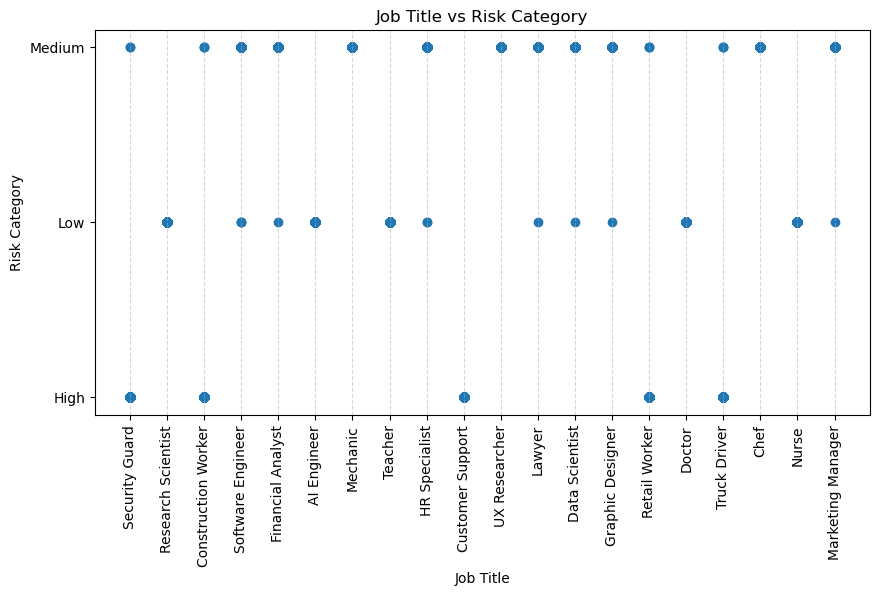

In [14]:
plt.figure(figsize=(10,5))
plt.scatter(df1["Job_Title"], df1["Risk_Category"])
plt.xlabel("Job Title")
plt.xticks(rotation=90)
plt.title("Job Title vs Risk Category")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.ylabel("Risk Category")

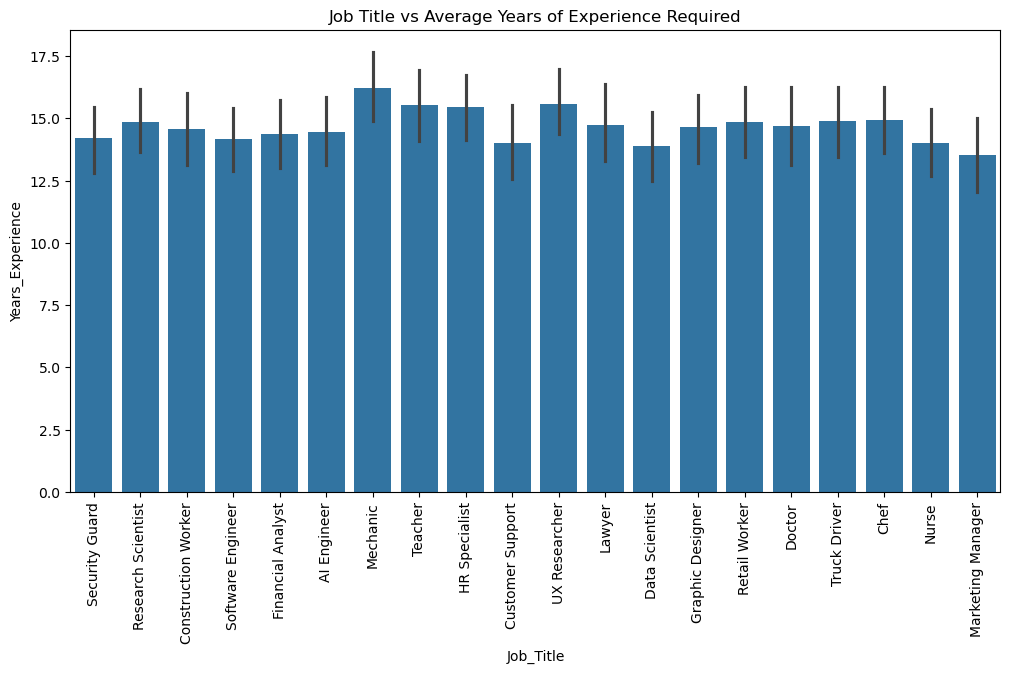

In [15]:
plt.figure(figsize = (12,6))
sns.barplot(x = "Job_Title", y = "Years_Experience" , data=df1)
plt.title("Job Title vs Average Years of Experience Required")
plt.xticks(rotation = 90)
plt.show()

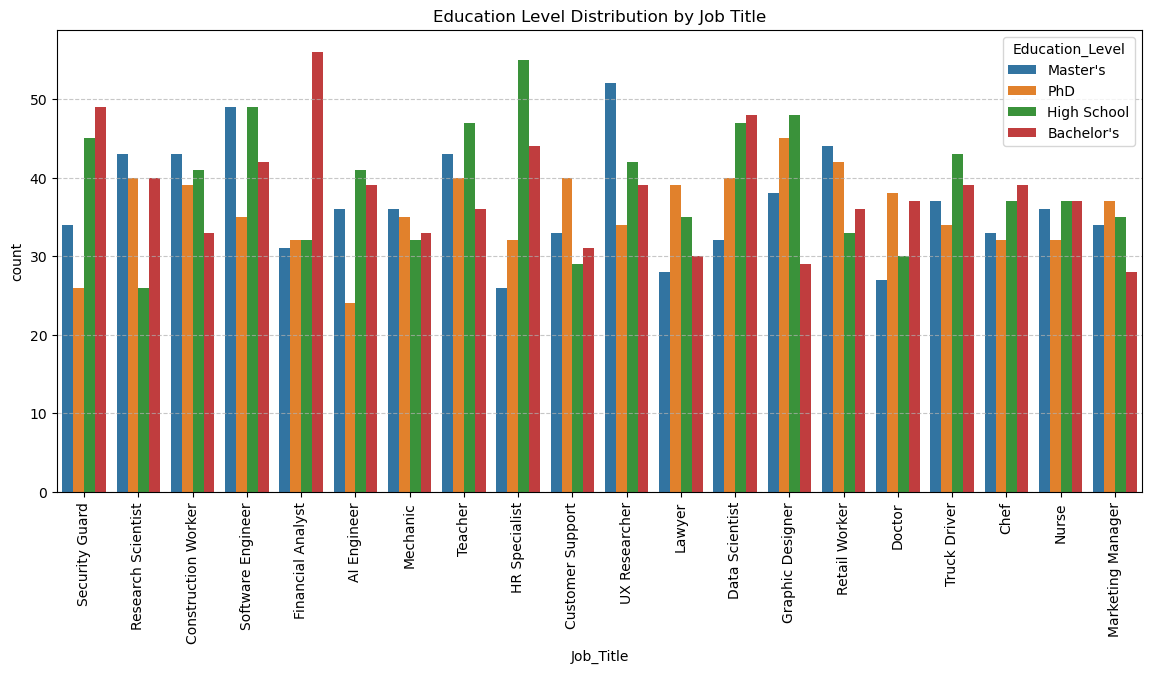

In [16]:
plt.figure(figsize=(14,6))
sns.countplot(x="Job_Title", hue="Education_Level", data=df1)
plt.title("Education Level Distribution by Job Title")
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

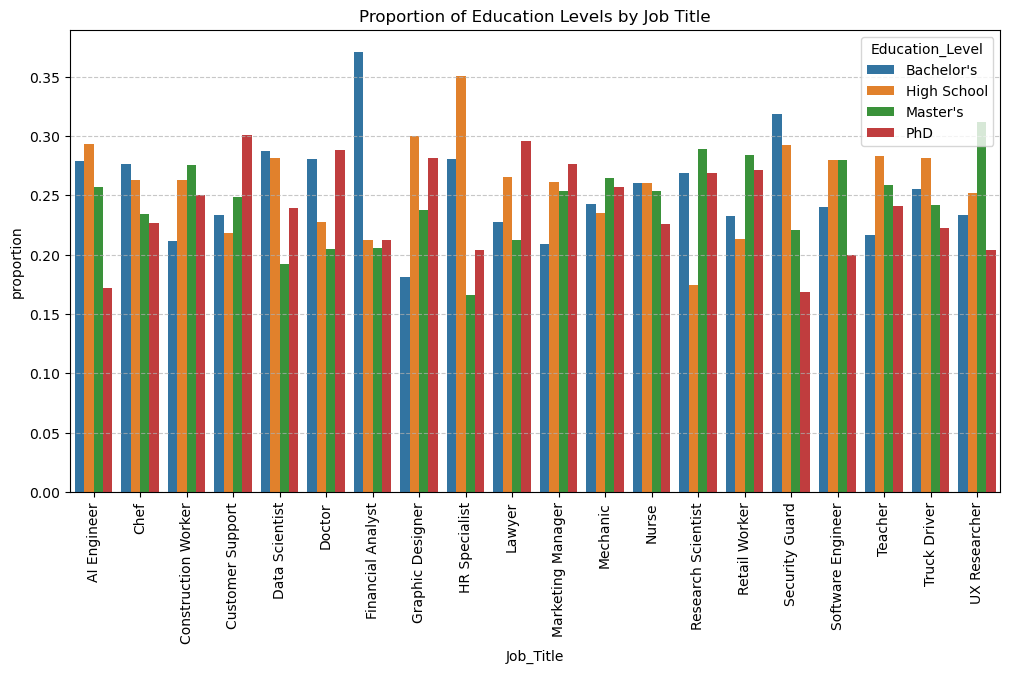

In [17]:
edu_counts = (df1.groupby(["Job_Title", "Education_Level"]).size().groupby(level=0).apply(lambda x: x / x.sum()).droplevel(0).reset_index(name="proportion"))

plt.figure(figsize=(12,6))
sns.barplot(x="Job_Title", y="proportion", hue="Education_Level", data=edu_counts)
plt.title("Proportion of Education Levels by Job Title")
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [18]:
new_df = df.drop("Education_Level", axis = 1)

In [19]:
X = new_df.drop("Risk_Category", axis = 1)
X.shape

(3000, 16)

In [20]:
y = new_df.Risk_Category
y.shape

(3000,)

In [21]:
dummies = pd.get_dummies(X["Job_Title"], dtype = int)
dummies

,AI Engineer,Chef,Construction Worker,Customer Support,Data Scientist,Doctor,Financial Analyst,Graphic Designer,HR Specialist,Lawyer,Marketing Manager,Mechanic,Nurse,Research Scientist,Retail Worker,Security Guard,Software Engineer,Teacher,Truck Driver,UX Researcher
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
2,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
4,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2996,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2997,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2998,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0


In [22]:
dummies = dummies.drop("UX Researcher", axis = 1)

In [23]:
X = pd.concat([X, dummies], axis = 1)
X = X.drop("Job_Title", axis = 1)
X.shape

(3000, 34)

In [24]:
from sklearn.preprocessing import LabelEncoder

In [25]:
le = LabelEncoder()

In [26]:
y = le.fit_transform(y)

In [27]:
y

array([0, 1, 0, ..., 2, 2, 2], shape=(3000,))

In [28]:
from sklearn.model_selection import train_test_split

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, shuffle = True)

In [30]:
X_train.head()

,Average_Salary,Years_Experience,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Skill_1,Skill_2,Skill_3,Skill_4,Skill_5,...,Lawyer,Marketing Manager,Mechanic,Nurse,Research Scientist,Retail Worker,Security Guard,Software Engineer,Teacher,Truck Driver
2796,90037,11,0.67,1.48,0.79,0.30,0.09,0.22,0.28,0.34,...,0,0,0,0,0,0,1,0,0,0
1930,127071,20,0.66,0.81,0.41,0.81,0.98,0.77,0.52,0.44,...,0,0,0,0,0,0,0,0,0,0
1965,80608,17,0.06,0.56,0.45,0.19,0.93,0.58,0.29,0.70,...,0,0,0,0,0,0,0,1,0,0
765,81142,16,0.59,0.85,0.82,0.60,0.47,0.70,0.43,0.20,...,0,0,0,0,0,0,0,0,0,0
2460,37612,16,0.04,1.19,0.30,0.92,0.68,0.84,0.26,0.62,...,0,0,0,1,0,0,0,0,0,0


In [31]:
y_train.shape

(2400,)

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [33]:
model = make_pipeline(StandardScaler(), LogisticRegression(solver='liblinear', max_iter = 1000))
model = model.fit(X_train, y_train)

C:\Users\enock\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(


In [34]:
model.score(X_test, y_test)

0.995

In [35]:
y_pred = model.predict(X_test)
y_pred

array([2, 2, 2, 0, 1, 0, 2, 0, 2, 0, 0, 0, 0, 2, 2, 2, 2, 2, 0, 0, 0, 2,
       2, 0, 2, 0, 1, 2, 2, 2, 2, 2, 2, 2, 0, 2, 1, 2, 2, 0, 2, 1, 2, 1,
       0, 2, 2, 1, 0, 2, 0, 2, 2, 2, 0, 0, 1, 0, 2, 0, 0, 1, 1, 2, 0, 0,
       2, 2, 0, 0, 2, 2, 2, 2, 0, 2, 2, 0, 2, 2, 2, 1, 0, 2, 0, 2, 0, 0,
       2, 2, 1, 0, 2, 0, 2, 2, 2, 1, 1, 2, 2, 2, 0, 0, 2, 1, 1, 1, 2, 0,
       1, 1, 2, 1, 1, 0, 0, 0, 0, 0, 2, 1, 2, 2, 2, 0, 2, 2, 0, 2, 1, 2,
       1, 2, 1, 1, 2, 0, 2, 1, 1, 2, 2, 1, 0, 2, 2, 1, 2, 1, 2, 2, 2, 2,
       1, 2, 1, 2, 0, 2, 1, 2, 2, 0, 1, 0, 2, 2, 0, 2, 2, 1, 0, 2, 2, 0,
       2, 1, 0, 1, 1, 2, 2, 0, 0, 2, 1, 2, 1, 1, 0, 0, 1, 2, 2, 2, 1, 0,
       1, 0, 0, 0, 2, 1, 0, 1, 2, 0, 1, 1, 2, 2, 1, 1, 2, 0, 2, 1, 2, 2,
       0, 2, 1, 2, 0, 0, 1, 2, 2, 2, 1, 2, 1, 1, 2, 2, 2, 0, 0, 2, 2, 2,
       0, 1, 1, 2, 0, 2, 1, 1, 2, 2, 0, 1, 0, 2, 2, 1, 2, 2, 2, 2, 0, 0,
       1, 1, 1, 1, 1, 2, 2, 2, 2, 0, 2, 0, 2, 2, 0, 2, 2, 0, 2, 2, 2, 1,
       2, 1, 0, 2, 1, 2, 2, 1, 1, 0, 2, 0, 2, 2, 0,

In [36]:
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score, f1_score, precision_score, recall_score)

In [37]:
cm = confusion_matrix(y_test, y_pred)

In [38]:
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

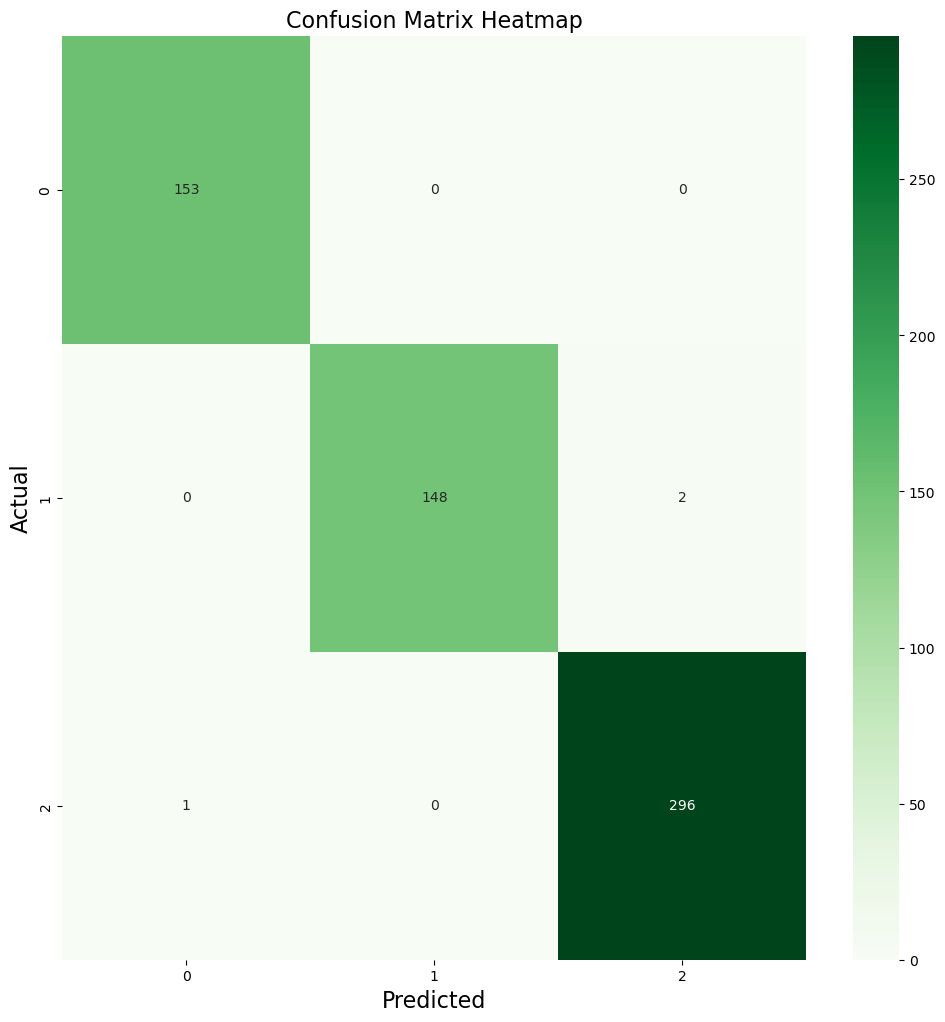

In [39]:
plt.figure(figsize=(12,12))
sns.heatmap(cm, annot=True, fmt='g', cmap="Greens")
plt.title('Confusion Matrix Heatmap', fontsize=16)
plt.xlabel('Predicted', fontsize=16)
plt.ylabel('Actual', fontsize=16)
plt.show()

In [40]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='macro')
recall = recall_score(y_test, y_pred, average='macro')
f1_score = f1_score(y_test, y_pred, average='macro')

print(f"Accuracy = {accuracy}")
print(f"Precision = {precision}")
print(f"Recall = {recall}")
print(f"f1_score = {f1_score}")

Accuracy = 0.995
Precision = 0.9955983613701734
Recall = 0.9944332210998877
f1_score = 0.994996414935692
